# Terrain-aware MDV `RATE_HYBRID` → reference-grid NetCDF

Converts **one** polar MDV rainfall-rate volume to a Cartesian rainfall-rate product (**mm/h**), using the lowest elevation whose beam center remains at least `MIN_CLEARANCE_M` above terrain along the entire radial. Output matches the **horizontal grid coordinates and dimensions** of a supplied reference NetCDF.

**Prototype limitations:** coarse 0.1° DEM (~11 km), beam-center rather than partial-beam blockage, 4/3-Earth propagation, nearest-gate sampling, no attenuation/gauge correction, and no rainfall accumulation. Missing radar values must be distinguished from true zero rainfall; the notebook prints a zero-value diagnostic. **Do not treat this as validated operational QPE.**

In [ ]:
# Run once if packages are missing:
# %pip install arm_pyart numpy scipy xarray netCDF4 matplotlib pyproj

In [1]:
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates
from pyproj import Geod
from pyart.io.mdv_common import MdvFile

MDV_FILE = Path('/Volumes/Rain/LiCie/projDir/data/mdv/radarPolar/derived/sur/20190206/070402.mdv')
TERRAIN_NPZ = Path('/Volumes/Rain/world_terrain_decoded.npz')
REFERENCE_NC = Path('../../data/example_grids/eg_radar_grid.nc')  # CHANGE THIS
OUTPUT_NC = Path('rate_hybrid_terrain_aware.nc')

FIELD = 'RATE_HYBRID'
MIN_CLEARANCE_M = 300.0
NEAR_RADAR_IGNORE_M = 1000.0  # avoid zero-range DEM/radar-height mismatch
MAX_RADAR_RANGE_M = 250_000.0
MAX_GATE_OFFSET_M = 1_000.0   # nearest range-gate tolerance
K_EARTH = 4.0 / 3.0
EARTH_RADIUS_M = 6_371_000.0
# Set True only if you have verified that zero means missing in THIS field.
MASK_ZERO_RAIN = False

for p in (MDV_FILE, TERRAIN_NPZ, REFERENCE_NC):
    if not p.is_file():
        raise FileNotFoundError(f'Missing input: {p}')


## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of Energy Office of Science as part of
## the Atmospheric Radiation Measurement (ARM) User Facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



## 1. Read radar and check field layout

In [2]:
mdv = MdvFile(str(MDV_FILE))
field_index = next(i for i, h in enumerate(mdv.field_headers)
                   if h['field_name'].strip() == FIELD)
h = mdv.field_headers[field_index]
v = mdv.vlevel_headers[field_index]
nx, ny, nz = (int(h[k]) for k in ('nx','ny','nz'))
elevations = np.asarray(v['level'][:nz], dtype=float)
radar_lat = float(mdv.master_header['sensor_lat'])
radar_lon = float(mdv.master_header['sensor_lon'])
radar_alt_m = float(mdv.master_header['sensor_alt']) * 1000.0
ranges_m = (float(h['grid_minx']) + np.arange(nx) * float(h['grid_dx'])) * 1000
azimuths = (float(h['grid_miny']) + np.arange(ny) * float(h['grid_dy'])) % 360
if not np.all(np.diff(elevations) > 0):
    raise ValueError('Elevation angles not strictly ascending; inspect vlevel header')
if not np.all(np.diff(ranges_m) > 0):
    raise ValueError('Range gates not ascending')
if abs(float(h['grid_dy']) - 1.0) > 1e-3 or ny != 360:
    raise ValueError('This prototype assumes 360 azimuths at 1-degree spacing')
raw = np.ma.asarray(mdv.read_a_field(field_index))
if raw.shape == (nz,ny,nx):
    pass
elif raw.shape == (ny,nx,nz):
    raw = np.moveaxis(raw,-1,0)
elif raw.shape == (nx,ny,nz):
    raw = np.transpose(raw,(2,1,0))
else:
    raise ValueError(f'Unexpected field shape {raw.shape}, expected {(nz,ny,nx)}')
rain = np.ma.filled(raw,np.nan).astype(np.float32)
rain[~np.isfinite(rain) | (rain < 0)] = np.nan
if MASK_ZERO_RAIN:
    rain[rain == 0] = np.nan
print('Radar:',radar_lat,radar_lon,'altitude m:',radar_alt_m)
print('Rain shape:',rain.shape,'units:',h['units'])
print('Elevations:',elevations)
print('Finite:',np.isfinite(rain).sum(),'zero:',np.count_nonzero(rain==0),
      'positive:',np.count_nonzero(rain>0))
print('Finite min/max:',np.nanmin(rain),np.nanmax(rain))
print('Header missing/bad:',h['missing_data_value'],h['bad_data_value'])
print('WARNING: Header missing/bad are both zero. Inspect the zero count and data before interpreting zero as no rain.')

Radar: -2.158076047897339 30.112340927124023 altitude m: 1616.0000562667847
Rain shape: (11, 360, 1042) units: mm/hr
Elevations: [ 0.5         1.48000002  2.5         3.5         4.5         6.
  8.         11.         15.         22.         32.        ]
Finite: 441610 zero: 0 positive: 441610
Finite min/max: 0.099999994 250.0
Header missing/bad: 0.0 0.0


## 2. Read decoded terrain and validate the radar neighborhood

In [3]:
with np.load(TERRAIN_NPZ) as dem:
    terrain = np.asarray(dem['elevation'],dtype=np.float32)
    lon0,lat0,dlon,dlat = (float(dem[k]) for k in ('lon0','lat0','dx','dy'))
if terrain.ndim != 2 or dlon <= 0 or dlat <= 0:
    raise ValueError('Expected 2D DEM and positive grid spacing')

def sample_dem(lons,lats):
    """Bilinear DEM lookup; NaN outside coverage or where DEM cells are missing."""
    lons,lats=np.broadcast_arrays(np.asarray(lons),np.asarray(lats))
    col=(lons-lon0)/dlon
    row=(lats-lat0)/dlat
    valid=(col>=0)&(col<=terrain.shape[1]-1)&(row>=0)&(row<=terrain.shape[0]-1)
    # Bilinear interpolation of values and valid-data weights.
    coords=np.array([np.clip(row,0,terrain.shape[0]-1).ravel(),
                     np.clip(col,0,terrain.shape[1]-1).ravel()])
    good=np.isfinite(terrain)
    numer=map_coordinates(np.where(good,terrain,0),coords,order=1,mode='nearest')
    denom=map_coordinates(good.astype(float),coords,order=1,mode='nearest')
    out=np.where(denom>0.999,numer,np.nan).reshape(lons.shape)
    return np.where(valid,out,np.nan)

radar_dem=float(sample_dem(radar_lon,radar_lat))
print('DEM shape:',terrain.shape,'finite %:',100*np.isfinite(terrain).mean())
print('DEM range:',np.nanmin(terrain),np.nanmax(terrain))
print('DEM at radar:',radar_dem,'m; radar altitude:',radar_alt_m,'m')
if not np.isfinite(radar_dem) or not (500 <= radar_dem <= 3500):
    raise ValueError('DEM near radar implausible; stop and inspect terrain decoding/georeferencing')
if abs(radar_dem-radar_alt_m)>1000:
    print('WARNING: large DEM vs radar-altitude difference; verify vertical datums and coarse-grid bias.')

DEM shape: (1800, 3600) finite %: 100.0
DEM range: -450.0 8500.0
DEM at radar: 1382.3062744140625 m; radar altitude: 1616.0000562667847 m


## 3. Terrain obstruction along each radial

Exclude the first 1 km from blockage assessment to avoid the zero-range radar-site DEM mismatch. This is an approximate workaround; inspect the diagnostics and use a finer DEM for scientific analysis.


In [4]:
geod=Geod(ellps='WGS84')
# Geodesic endpoints for every azimuth/range sample.
az_grid=np.broadcast_to(azimuths[:,None],(ny,nx))
range_grid=np.broadcast_to(ranges_m[None,:],(ny,nx))
radial_lon,radial_lat,_=geod.fwd(
    np.full((ny,nx),radar_lon),np.full((ny,nx),radar_lat),az_grid,range_grid)
terrain_radial=sample_dem(radial_lon,radial_lat)

def beam_center_asl(range_m,elevation_deg):
    elev=np.deg2rad(elevation_deg)
    re=K_EARTH*EARTH_RADIUS_M
    return radar_alt_m + np.sqrt(range_m**2+re**2+2*range_m*re*np.sin(elev))-re

# Diagnostic: DEM/beam clearance at the first gates.
print('First gate ranges (m):', ranges_m[:8])
print('First-gate terrain (m):', terrain_radial[0, :8])
print('Radar DEM vs instrument altitude (m):', radar_dem, radar_alt_m)
print('DEM valid fraction along rays:', np.isfinite(terrain_radial).mean())

usable=np.zeros((nz,ny,nx),dtype=bool)
height_agl=np.full((nz,ny,nx),np.nan,dtype=np.float32)
near = ranges_m < NEAR_RADAR_IGNORE_M
for k,elev in enumerate(elevations):
    height=beam_center_asl(ranges_m,elev)[None,:]-terrain_radial
    height_agl[k]=height
    clear=np.isfinite(height)&(height>=MIN_CLEARANCE_M)
    # Do not let the radar-site cell or a sub-km DEM mismatch
    # invalidate an entire radial. This is an approximation.
    clear[:,near]=True
    usable[k]=np.logical_and.accumulate(clear,axis=1)
    usable[k,:,near]=False  # never output values inside ignored zone
    print(f'{elev:5.2f} degrees: usable gates {100*usable[k].mean():5.1f}%; '
          f'clear beyond exclusion {100*clear[:,~near].mean():5.1f}%')

if not np.any(usable):
    raise ValueError('All sweeps blocked after near-radar exclusion. Check DEM georeferencing, '
                     'terrain elevations, radar altitude, and clearance threshold.')

selected=np.full((ny,nx),np.nan,dtype=np.float32)
selected_elev=np.full((ny,nx),np.nan,dtype=np.float32)
selected_agl=np.full((ny,nx),np.nan,dtype=np.float32)
for k,elev in enumerate(elevations):
    ok=usable[k]&np.isfinite(rain[k])&~np.isfinite(selected)
    selected[ok]=rain[k][ok]
    selected_elev[ok]=elev
    selected_agl[ok]=height_agl[k][ok]
print('Usable rainfall gates:',np.isfinite(selected).sum(),'/',selected.size)

First gate ranges (m): [   0.          239.8339659   479.6679318   719.50189769  959.33586359
 1199.16982949 1439.00379539 1678.83776128]
First-gate terrain (m): [1382.3063 1383.6584 1385.0105 1386.3627 1387.7148 1389.067  1390.4191
 1391.7712]
Radar DEM vs instrument altitude (m): 1382.3062744140625 1616.0000562667847
DEM valid fraction along rays: 1.0
 0.50 degrees: usable gates   0.0%; clear beyond exclusion  94.9%
 1.48 degrees: usable gates   0.0%; clear beyond exclusion  99.3%
 2.50 degrees: usable gates   0.0%; clear beyond exclusion  99.8%
 3.50 degrees: usable gates  69.9%; clear beyond exclusion 100.0%
 4.50 degrees: usable gates  99.5%; clear beyond exclusion 100.0%
 6.00 degrees: usable gates  99.5%; clear beyond exclusion 100.0%
 8.00 degrees: usable gates  99.5%; clear beyond exclusion 100.0%
11.00 degrees: usable gates  99.5%; clear beyond exclusion 100.0%
15.00 degrees: usable gates  99.5%; clear beyond exclusion 100.0%
22.00 degrees: usable gates  99.5%; clear beyond e

## 4. Read the reference NetCDF horizontal grid

Supports 1D `lat`/`lon` (or `latitude`/`longitude`) and 2D geographic coordinate arrays. **Projected x/y-only grids require an explicit CRS and are not automatically guessed.**

In [5]:
ref=xr.open_dataset(REFERENCE_NC)
print(ref)
lat_name=next((s for s in ('lat','latitude') if s in ref.variables),None)
lon_name=next((s for s in ('lon','longitude') if s in ref.variables),None)
if lat_name is None or lon_name is None:
    raise ValueError('Reference must contain lat/lon coordinate variables. Upload it to adapt projected grids.')
lat_da,lon_da=ref[lat_name],ref[lon_name]
if lat_da.ndim==1 and lon_da.ndim==1:
    target_lon,target_lat=np.meshgrid(lon_da.values,lat_da.values)
    dims=(lat_da.dims[0],lon_da.dims[0])
    out_coords={dims[0]:ref[dims[0]],dims[1]:ref[dims[1]]}
elif lat_da.ndim==2 and lon_da.ndim==2 and lat_da.dims==lon_da.dims:
    target_lat,target_lon=lat_da.values,lon_da.values
    dims=lat_da.dims
    out_coords={d:ref[d] if d in ref.variables else np.arange(ref.sizes[d]) for d in dims}
    out_coords[lat_name]=lat_da
    out_coords[lon_name]=lon_da
else:
    raise ValueError('Unsupported reference lat/lon layout; inspect the printed dataset')
if target_lat.shape!=target_lon.shape:
    raise ValueError('Reference latitude/longitude shape mismatch')
print('Output dimensions:',dims,'shape:',target_lat.shape)

<xarray.Dataset> Size: 4MB
Dimensions:      (y: 396, x: 396)
Coordinates:
  * y            (y) float64 3kB -1.98e+05 -1.97e+05 ... 1.96e+05 1.97e+05
  * x            (x) float64 3kB -1.98e+05 -1.97e+05 ... 1.96e+05 1.97e+05
    lon          (y, x) float64 1MB ...
    lat          (y, x) float64 1MB ...
    central_lon  float64 8B ...
    central_lat  float64 8B ...
    time         datetime64[ns] 8B ...
Data variables:
    qpe          (y, x) float64 1MB ...
Output dimensions: ('y', 'x') shape: (396, 396)


## 5. Sample selected polar rainfall on the target grid

Nearest radar range gate and azimuth bin; no interpolation across missing or blocked sectors. Pixels outside nominal range or beyond the gate-distance tolerance remain missing.

In [ ]:
az12,az21,dist=geod.inv(np.full(target_lon.shape,radar_lon),
                            np.full(target_lat.shape,radar_lat),target_lon,target_lat)
az=(az12+360)%360
# nearest azimuth bin with circular wrap
azi=np.mod(np.rint((az-float(h['grid_miny']))/float(h['grid_dy'])).astype(int),ny)
rg_float=(dist/1000-float(h['grid_minx']))/float(h['grid_dx'])
ri=np.rint(rg_float).astype(int)
ri_safe=np.clip(ri,0,nx-1)
# distance from the actual sampled polar gate center to the target
sample_az=azimuths[azi]
sample_range=ranges_m[ri_safe]
angular=np.deg2rad(((az-sample_az+180)%360)-180)
gate_offset=np.sqrt((dist-sample_range)**2+(dist*angular)**2)
valid_geo=(np.isfinite(target_lon)&np.isfinite(target_lat)&
           (dist<=MAX_RADAR_RANGE_M)&(ri>=0)&(ri<nx)&
           (gate_offset<=MAX_GATE_OFFSET_M))

def sample_selected(a):
    out=np.asarray(a[azi,ri_safe],dtype=np.float32).copy()
    out[~valid_geo]=np.nan
    return out

out_rain=sample_selected(selected)
out_elev=sample_selected(selected_elev)
out_agl=sample_selected(selected_agl)
print('Valid output pixels:',np.isfinite(out_rain).sum(),'/',out_rain.size)
print('Output min/max mm/h:',np.nanmin(out_rain) if np.isfinite(out_rain).any() else None,
      np.nanmax(out_rain) if np.isfinite(out_rain).any() else None)

Valid output pixels: 33995 / 156816
Output min/max mm/h: 0.099999994 6.18


## 6. Save NetCDF (mm/h)

In [7]:
out=xr.Dataset(
    data_vars={
      'rain_rate':(dims,out_rain,{'units':'mm/h','long_name':'Terrain-aware radar rainfall rate'}),
      'selected_elevation':(dims,out_elev,{'units':'degree','long_name':'Selected radar elevation angle'}),
      'beam_height_agl':(dims,out_agl,{'units':'m','long_name':'Selected beam center height above terrain'}),
      'radar_coverage':(dims,np.isfinite(out_rain).astype('uint8'),
                        {'long_name':'1 where terrain-aware rainfall estimate is available','flag_values':[0,1]})
    },coords=out_coords,
    attrs={'source_mdv':str(MDV_FILE),'radar_field':FIELD,
           'method':'lowest clear beam center along complete radar radial; nearest polar gate',
           'minimum_clearance_m':MIN_CLEARANCE_M,
           'terrain_source':str(TERRAIN_NPZ),
           'limitations':'Coarse terrain; no fractional beam blockage; no gauge correction; no temporal accumulation'})
# Preserve time as metadata; no time dimension is added to the reference horizontal grid.
from datetime import datetime,timezone
out.attrs['radar_time_utc']=datetime.fromtimestamp(
    int(mdv.master_header['time_centroid']),timezone.utc).isoformat()
OUTPUT_NC.parent.mkdir(parents=True,exist_ok=True)
out.to_netcdf(OUTPUT_NC,encoding={k:{'zlib':True,'complevel':4} for k in out.data_vars})
print('Saved:',OUTPUT_NC.resolve())
print(out)
ref.close()

Saved: /Users/matthewwright/git/SEWAA-forecasts-Rwanda_radar/SEWAA-forecasts/code/ifs+cgan_radar/rate_hybrid_terrain_aware.nc
<xarray.Dataset> Size: 5MB
Dimensions:             (y: 396, x: 396)
Coordinates:
  * y                   (y) float64 3kB -1.98e+05 -1.97e+05 ... 1.97e+05
  * x                   (x) float64 3kB -1.98e+05 -1.97e+05 ... 1.97e+05
    lon                 (y, x) float64 1MB 28.33 28.34 28.35 ... 31.87 31.88
    lat                 (y, x) float64 1MB -3.947 -3.947 ... -0.3757 -0.3757
    central_lon         float64 8B 30.11
    central_lat         float64 8B -2.158
    time                datetime64[ns] 8B 2026-06-26T12:00:00
Data variables:
    rain_rate           (y, x) float32 627kB nan nan nan nan ... nan nan nan nan
    selected_elevation  (y, x) float32 627kB nan nan nan nan ... nan nan nan nan
    beam_height_agl     (y, x) float32 627kB nan nan nan nan ... nan nan nan nan
    radar_coverage      (y, x) uint8 157kB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0
Attribut

## 7. Diagnostic plots

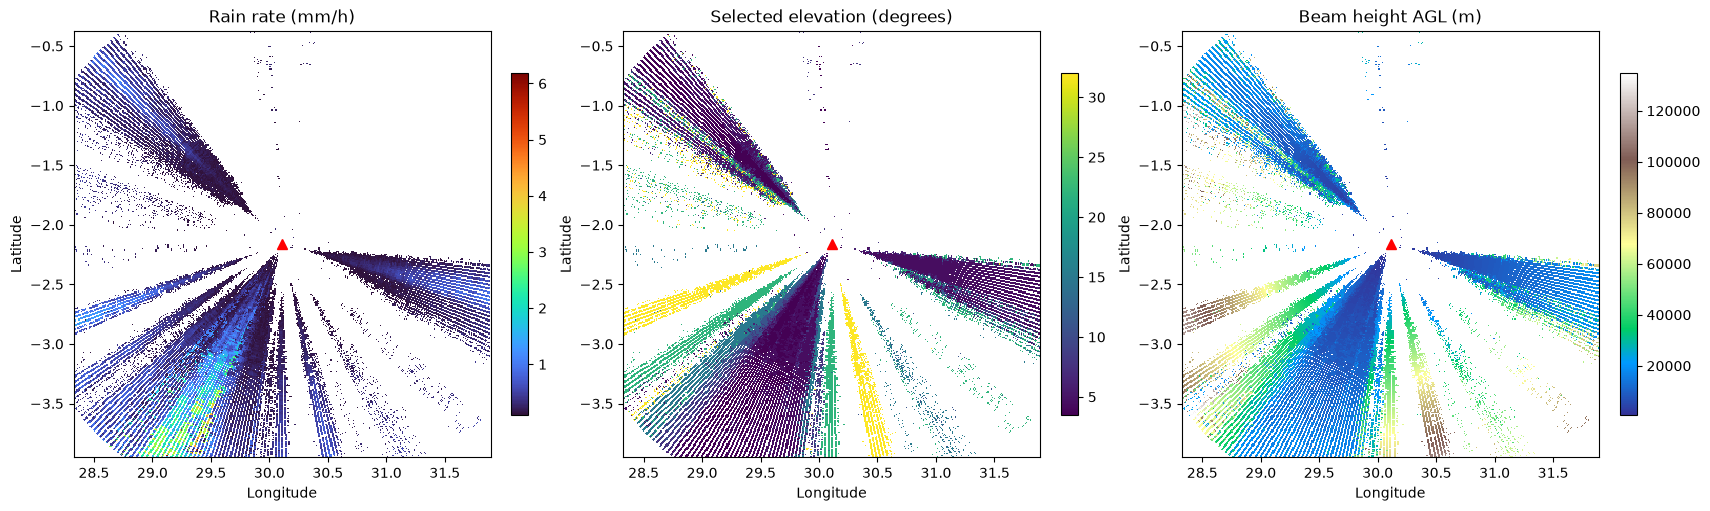

Selected elevation distribution:
 3.50 deg: 5967 pixels
 4.50 deg: 9706 pixels
 6.00 deg: 2337 pixels
 8.00 deg: 2425 pixels
11.00 deg: 1615 pixels
15.00 deg: 3558 pixels
22.00 deg: 4834 pixels
32.00 deg: 3553 pixels
IMPORTANT: inspect suspicious zero rainfall, terrain blockage sectors and DEM coverage.


In [8]:
fig,axes=plt.subplots(1,3,figsize=(17,5),constrained_layout=True)
for ax,values,title,cmap in zip(
    axes,(out_rain,out_elev,out_agl),
    ('Rain rate (mm/h)','Selected elevation (degrees)','Beam height AGL (m)'),
    ('turbo','viridis','terrain')):
    im=ax.pcolormesh(target_lon,target_lat,values,shading='auto',cmap=cmap)
    ax.plot(radar_lon,radar_lat,'r^',markersize=7)
    ax.set_title(title);ax.set_xlabel('Longitude');ax.set_ylabel('Latitude')
    fig.colorbar(im,ax=ax,shrink=0.8)
plt.show()
print('Selected elevation distribution:')
for elev in elevations:
    count=np.count_nonzero(np.isclose(out_elev,elev,atol=0.01))
    if count: print(f'{elev:5.2f} deg: {count} pixels')
print('IMPORTANT: inspect suspicious zero rainfall, terrain blockage sectors and DEM coverage.')